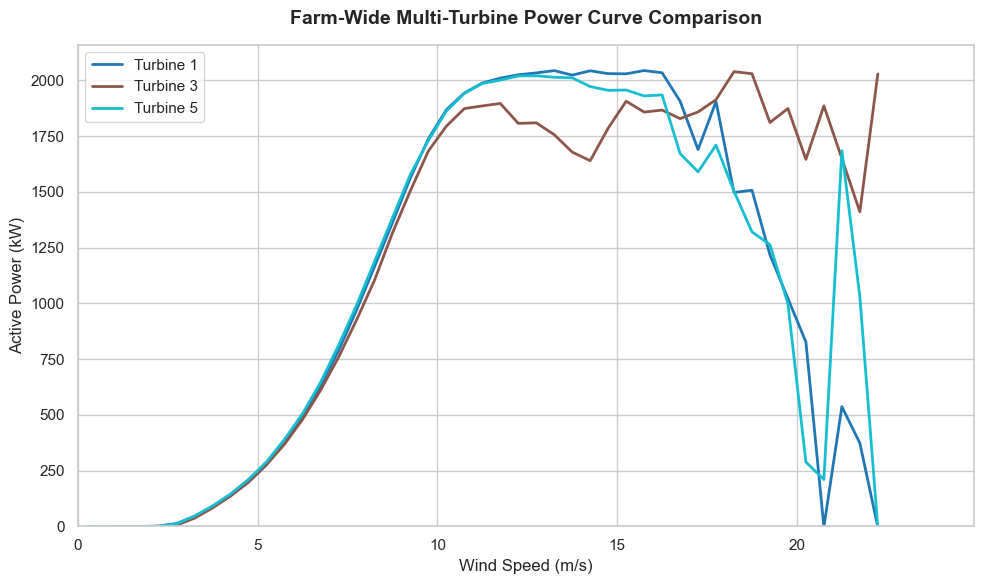

In [1]:
import sys
from pathlib import Path

# Add root directory to path
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_scada_data, filter_operational_data
from src.plotting import plot_multi_turbine_power_curves
import matplotlib.pyplot as plt

# 1. Dictionary to hold multi-turbine datasets
turbine_data = {}
turbine_ids = ['1', '3', '5']  # Adjust based on your filenames (e.g., Kelmarsh_SCADA_2019_T1.csv)

for t_id in turbine_ids:
    file_path = Path(f"../data/Turbine_Data_Kelmarsh_{t_id}_2020-01-01_-_2021-01-01.csv")
    try:
        df = load_scada_data(file_path)
        turbine_data[f"Turbine {t_id}"] = filter_operational_data(df)
    except FileNotFoundError:
        print(f"File for {t_id} not found. Skipping...")

# 2. Plot comparison if data was successfully loaded
if turbine_data:
    fig, ax = plot_multi_turbine_power_curves(
        turbine_data, 
        wind_speed_col='Wind speed (m/s)', 
        power_col='Power (kW)'
    )
    plt.show()
else:
    print("Please ensure your multi-turbine CSV files are placed in the data/ folder.")